# Chord Diagram

**Family:** Flow &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Flow:* Show the volume or intensity of movement between states, stages, or places.

## Design purpose

Groups are placed as arcs around a circle and joined by ribbons whose width is proportional to the flow between them. It shows two-way flows in a matrix (A→B and B→A) compactly, including self-flows.

## When to use

- Show migration, trade, or transfers between a handful of entities in both directions
- Show inter-relationships within a square flow matrix
- Show at a glance which pairs dominate the exchange

## Avoid when

- There are more than ~10 groups (ribbons tangle)
- Precise values are needed (use a heatmap of the matrix)
- Flow is one-directional through stages (use a Sankey diagram)

## Alternatives

- Origin–destination heatmap
- Sankey diagram
- Network graph

## Design tips

- Color each ribbon by its origin group so direction is visible

## Example

Cross-border portfolio investment flows between five regions in a year (USD bn, illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch, Wedge

### Data

In [2]:
depts = ["N. America", "Europe", "Asia-Pacific", "Latin America", "Middle East"]
M = pd.DataFrame([[0, 120, 180, 40, 260],
                  [10, 0, 60, 25, 140],
                  [15, 70, 0, 50, 90],
                  [20, 45, 35, 0, 30],
                  [25, 50, 40, 60, 0]], index=depts, columns=depts)
M  # USD bn; rows = investor region, columns = destination

,N. America,Europe,Asia-Pacific,Latin America,Middle East
N. America,0,120,180,40,260
Europe,10,0,60,25,140
Asia-Pacific,15,70,0,50,90
Latin America,20,45,35,0,30
Middle East,25,50,40,60,0


### Plot

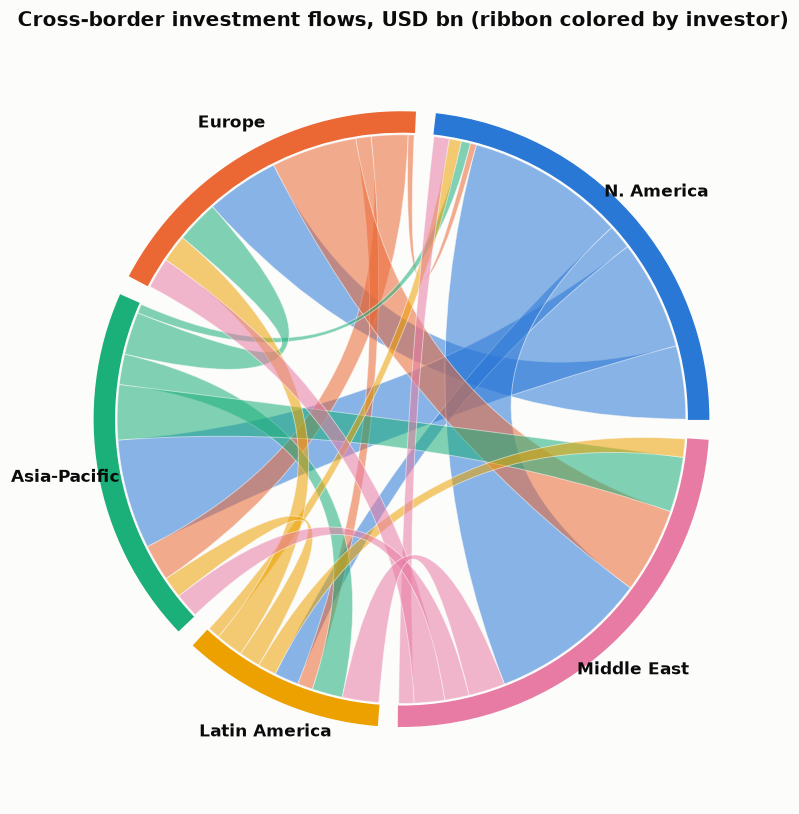

In [3]:
n = len(depts)
out_tot, in_tot = M.sum(axis=1).values, M.sum(axis=0).values
totals = out_tot + in_tot
gap = np.deg2rad(4)
scale = (2 * np.pi - n * gap) / totals.sum()
starts = np.concatenate([[0], np.cumsum(totals * scale + gap)[:-1]])
# each group's arc: first its outgoing part, then incoming part
out_pos = starts.copy()
in_pos = starts + out_tot * scale
fig, ax = plt.subplots(figsize=(7.5, 7.5))
R = 1.0
def pt(a, r=R):
    return (r * np.cos(a), r * np.sin(a))
for i in range(n):
    for j in range(n):
        v = M.iloc[i, j]
        if v == 0:
            continue
        w = v * scale
        a0, a1 = out_pos[i], out_pos[i] + w
        b0, b1 = in_pos[j], in_pos[j] + w
        out_pos[i] += w
        in_pos[j] += w
        rim1 = [pt(a) for a in np.linspace(a0, a1, 12)]
        rim2 = [pt(b) for b in np.linspace(b0, b1, 12)]
        verts = rim1 + [(0, 0), rim2[0]] + rim2[1:] + [(0, 0), rim1[0], rim1[0]]
        codes = ([MPath.MOVETO] + [MPath.LINETO] * 11 + [MPath.CURVE3, MPath.CURVE3]
                 + [MPath.LINETO] * 11 + [MPath.CURVE3, MPath.CURVE3, MPath.CLOSEPOLY])
        path = MPath(verts, codes)
        ax.add_patch(PathPatch(path, facecolor=PALETTE[i], alpha=0.55,
                               edgecolor="#fcfcfb", linewidth=0.6))
for i, name in enumerate(depts):
    a0, a1 = starts[i], starts[i] + totals[i] * scale
    ax.add_patch(Wedge((0, 0), 1.08, np.rad2deg(a0), np.rad2deg(a1), width=0.07,
                       color=PALETTE[i]))
    mid = (a0 + a1) / 2
    x, y = pt(mid, 1.2)
    ax.text(x, y, name, ha="center", va="center", fontsize=11, fontweight="bold")
ax.set_xlim(-1.35, 1.35)
ax.set_ylim(-1.35, 1.35)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Cross-border investment flows, USD bn (ribbon colored by investor)")
fig.tight_layout()
plt.show()

## How to read it

Each region's arc length is its total capital sent and received. A ribbon joins the investing region to the destination and takes the investor's color. The wide blue ribbons show North America is the largest source of cross-border investment.

---
Standalone script: [`chord_diagram.py`](chord_diagram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)